In [2]:
# ============================================================
# MEDIMATE KIDNEY WAITLIST — FINAL ANALYSIS
# CHUNK 1
#
# LOAD CLASSIFICATION + SURVIVAL OUTPUTS
# ============================================================

import os
import json
import zipfile
import pandas as pd
import numpy as np

from google.colab import files


# ============================================================
# PART 1 — UPLOAD BOTH ZIP FILES
# ============================================================

print(
    "Upload these two files:\n"
    "1. medimate_classification_modeling_outputs.zip\n"
    "2. medimate_survival_modeling_outputs.zip"
)

uploaded = files.upload()


print("\nUPLOADED FILES:")

for filename in uploaded.keys():
    print("-", filename)


# ============================================================
# PART 2 — IDENTIFY BOTH ZIP FILES
# ============================================================

classification_zip = None
survival_zip = None


for filename in uploaded.keys():

    lower_name = filename.lower()

    if (
        "classification" in lower_name
        and filename.lower().endswith(".zip")
    ):
        classification_zip = filename

    if (
        "survival" in lower_name
        and filename.lower().endswith(".zip")
    ):
        survival_zip = filename


if classification_zip is None:
    raise ValueError(
        "Classification ZIP was not found."
    )

if survival_zip is None:
    raise ValueError(
        "Survival ZIP was not found."
    )


print(
    "\nClassification ZIP:",
    classification_zip
)

print(
    "Survival ZIP:",
    survival_zip
)


# ============================================================
# PART 3 — CREATE OUTPUT FOLDERS
# ============================================================

classification_dir = (
    "/content/medimate_classification_outputs"
)

survival_dir = (
    "/content/medimate_survival_outputs"
)


os.makedirs(
    classification_dir,
    exist_ok=True
)

os.makedirs(
    survival_dir,
    exist_ok=True
)


# ============================================================
# PART 4 — EXTRACT BOTH ZIP FILES
# ============================================================

with zipfile.ZipFile(
    classification_zip,
    "r"
) as zip_ref:

    zip_ref.extractall(
        classification_dir
    )


with zipfile.ZipFile(
    survival_zip,
    "r"
) as zip_ref:

    zip_ref.extractall(
        survival_dir
    )


classification_files = sorted(
    os.listdir(
        classification_dir
    )
)

survival_files = sorted(
    os.listdir(
        survival_dir
    )
)


print(
    "\n=========================================="
)

print(
    "FILES EXTRACTED"
)

print(
    "=========================================="
)


print(
    "\nClassification files:",
    len(classification_files)
)

print(
    "Survival files:",
    len(survival_files)
)


# ============================================================
# PART 5 — SHOW EXTRACTED FILES
# ============================================================

print(
    "\nCLASSIFICATION OUTPUTS\n"
)

for filename in classification_files:
    print("-", filename)


print(
    "\nSURVIVAL OUTPUTS\n"
)

for filename in survival_files:
    print("-", filename)


# ============================================================
# PART 6 — LOAD FINAL SETTINGS
# ============================================================

classification_settings_path = os.path.join(
    classification_dir,
    "final_model_settings.json"
)

survival_settings_path = os.path.join(
    survival_dir,
    "final_survival_settings.json"
)


with open(
    classification_settings_path,
    "r"
) as f:

    classification_settings = json.load(f)


with open(
    survival_settings_path,
    "r"
) as f:

    survival_settings = json.load(f)


print(
    "\n=========================================="
)

print(
    "CLASSIFICATION FINAL SETTINGS"
)

print(
    "==========================================\n"
)


for key, value in classification_settings.items():

    print(
        f"{key}: {value}"
    )


print(
    "\n=========================================="
)

print(
    "SURVIVAL FINAL SETTINGS"
)

print(
    "==========================================\n"
)


for key, value in survival_settings.items():

    print(
        f"{key}: {value}"
    )


# ============================================================
# PART 7 — LOAD CLASSIFICATION RESULTS
# ============================================================

classification_model_comparison = pd.read_csv(
    os.path.join(
        classification_dir,
        "multi_model_validation_comparison.csv"
    )
)


classification_test_summary = pd.read_csv(
    os.path.join(
        classification_dir,
        "validation_vs_test_summary.csv"
    )
)


classification_subgroup_gaps = pd.read_csv(
    os.path.join(
        classification_dir,
        "subgroup_gap_summary.csv"
    )
)


classification_shap = pd.read_csv(
    os.path.join(
        classification_dir,
        "shap_original_feature_importance.csv"
    )
)


classification_cpra = pd.read_csv(
    os.path.join(
        classification_dir,
        "cpra_sensitivity_comparison.csv"
    )
)


# ============================================================
# PART 8 — LOAD SURVIVAL RESULTS
# ============================================================

survival_model_comparison = pd.read_csv(
    os.path.join(
        survival_dir,
        "survival_model_comparison.csv"
    )
)


survival_risk_groups = pd.read_csv(
    os.path.join(
        survival_dir,
        "final_1yr_risk_groups.csv"
    )
)


overall_competing_risk = pd.read_csv(
    os.path.join(
        survival_dir,
        "overall_competing_risk_summary.csv"
    )
)


survival_explainability = pd.read_csv(
    os.path.join(
        survival_dir,
        "xgboost_survival_explainability.csv"
    )
)


cox_hazard_ratios = pd.read_csv(
    os.path.join(
        survival_dir,
        "final_cox_hazard_ratios.csv"
    )
)


# ============================================================
# PART 9 — PRINT MODEL COMPARISONS
# ============================================================

print(
    "\n=========================================="
)

print(
    "CLASSIFICATION MODEL COMPARISON"
)

print(
    "==========================================\n"
)


print(
    classification_model_comparison
    .round(4)
    .to_string(
        index=False
    )
)


print(
    "\n=========================================="
)

print(
    "SURVIVAL MODEL COMPARISON"
)

print(
    "==========================================\n"
)


print(
    survival_model_comparison
    .round(4)
    .to_string(
        index=False
    )
)


# ============================================================
# PART 10 — CLASSIFICATION TEST RESULTS
# ============================================================

print(
    "\n=========================================="
)

print(
    "CLASSIFICATION VALIDATION VS TEST"
)

print(
    "==========================================\n"
)


print(
    classification_test_summary
    .round(4)
    .to_string(
        index=False
    )
)


# ============================================================
# PART 11 — SURVIVAL FINAL RISK GROUPS
# ============================================================

print(
    "\n=========================================="
)

print(
    "2024 SURVIVAL RISK GROUPS"
)

print(
    "==========================================\n"
)


print(
    survival_risk_groups
    .round(4)
    .to_string(
        index=False
    )
)


# ============================================================
# PART 12 — OVERALL COMPETING-RISK RESULTS
# ============================================================

print(
    "\n=========================================="
)

print(
    "OVERALL COMPETING-RISK RESULTS"
)

print(
    "==========================================\n"
)


print(
    overall_competing_risk
    .round(4)
    .to_string(
        index=False
    )
)


# ============================================================
# PART 13 — TOP CLASSIFICATION FEATURES
# ============================================================

print(
    "\n=========================================="
)

print(
    "TOP CLASSIFICATION FEATURES"
)

print(
    "==========================================\n"
)


print(
    classification_shap
    .head(10)
    .round(4)
    .to_string(
        index=False
    )
)


# ============================================================
# PART 14 — TOP SURVIVAL FEATURES
# ============================================================

print(
    "\n=========================================="
)

print(
    "TOP SURVIVAL FEATURES"
)

print(
    "==========================================\n"
)


print(
    survival_explainability
    .head(10)
    .round(4)
    .to_string(
        index=False
    )
)


# ============================================================
# PART 15 — IMPORTANT COX HAZARD RATIOS
# ============================================================

print(
    "\n=========================================="
)

print(
    "FINAL COX HAZARD RATIOS"
)

print(
    "==========================================\n"
)


print(
    cox_hazard_ratios
    .round(4)
    .to_string(
        index=False
    )
)


# ============================================================
# PART 16 — BASIC MASTER SUMMARY
# ============================================================

master_summary = pd.DataFrame(
    {
        "Analysis": [
            "Classification",
            "Survival"
        ],

        "Final_Model": [
            "XGBoost",
            "XGBoost Survival"
        ],

        "Validation_Year": [
            2023,
            2023
        ],

        "Test_Year": [
            2024,
            2024
        ],

        "CPRA_Used": [
            "No",
            "No"
        ]
    }
)


print(
    "\n=========================================="
)

print(
    "PRIMARY MODEL SUMMARY"
)

print(
    "==========================================\n"
)


print(
    master_summary
    .to_string(
        index=False
    )
)


# ============================================================
# FINAL CHECK
# ============================================================

print(
    "\n=========================================="
)

print(
    "CHUNK 1 COMPLETE"
)

print(
    "=========================================="
)


print(
    "\nBoth completed modeling pipelines "
    "were loaded successfully."
)

Upload these two files:
1. medimate_classification_modeling_outputs.zip
2. medimate_survival_modeling_outputs.zip


Saving medimate_survival_modeling_outputs.zip to medimate_survival_modeling_outputs (1).zip
Saving medimate_classification_modeling_outputs.zip to medimate_classification_modeling_outputs (1).zip

UPLOADED FILES:
- medimate_survival_modeling_outputs (1).zip
- medimate_classification_modeling_outputs (1).zip

Classification ZIP: medimate_classification_modeling_outputs (1).zip
Survival ZIP: medimate_survival_modeling_outputs (1).zip

FILES EXTRACTED

Classification files: 22
Survival files: 18

CLASSIFICATION OUTPUTS

- cpra_sensitivity_comparison.csv
- fairness_age.csv
- fairness_blood_type.csv
- fairness_ethcat.csv
- fairness_gender.csv
- fairness_region.csv
- final_model_settings.json
- final_xgboost_model.joblib
- final_xgboost_model.json
- logistic_regression_baseline.joblib
- multi_model_validation_comparison.csv
- random_forest_comparison.joblib
- shap_age_direction.csv
- shap_dialysis_direction.csv
- shap_ethcat_direction.csv
- shap_functional_status_direction.csv
- shap_origina

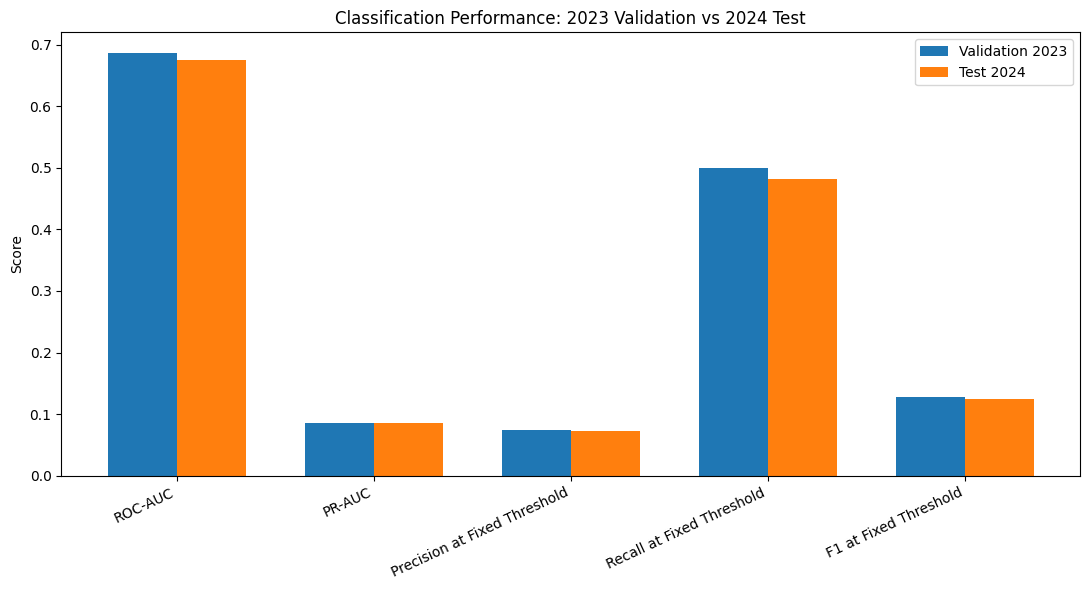

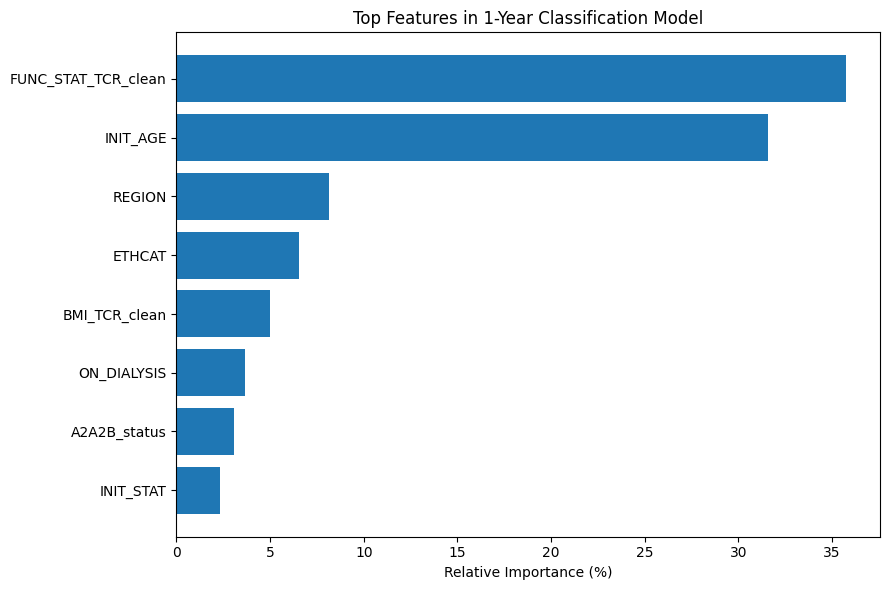

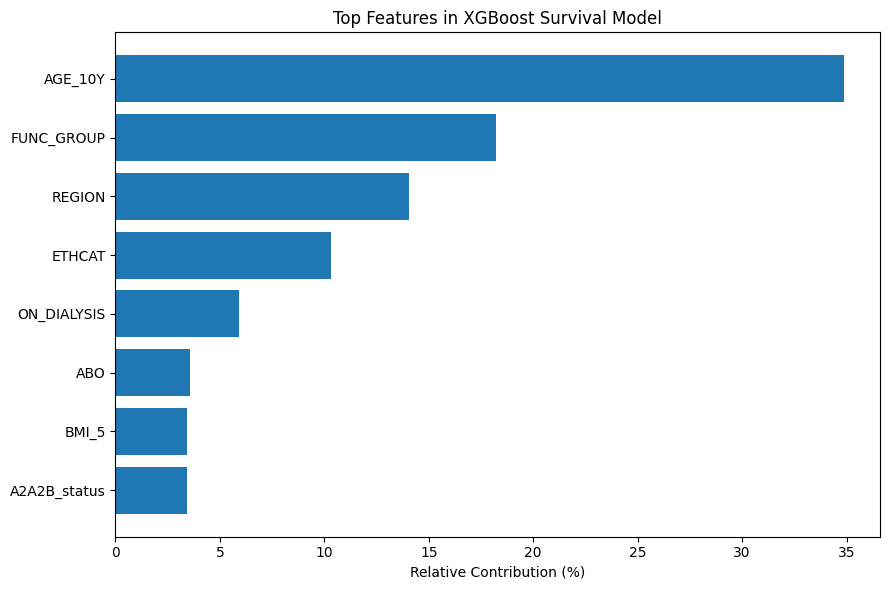

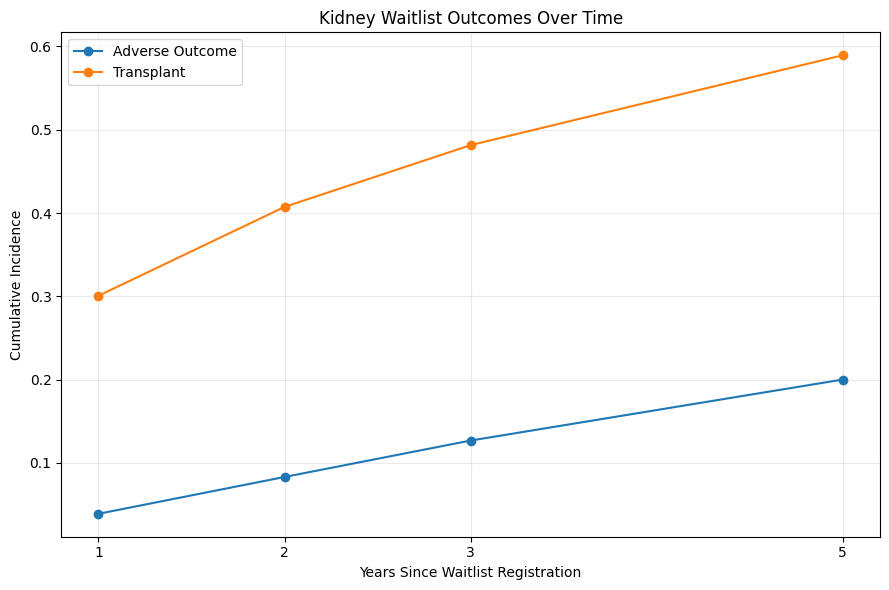

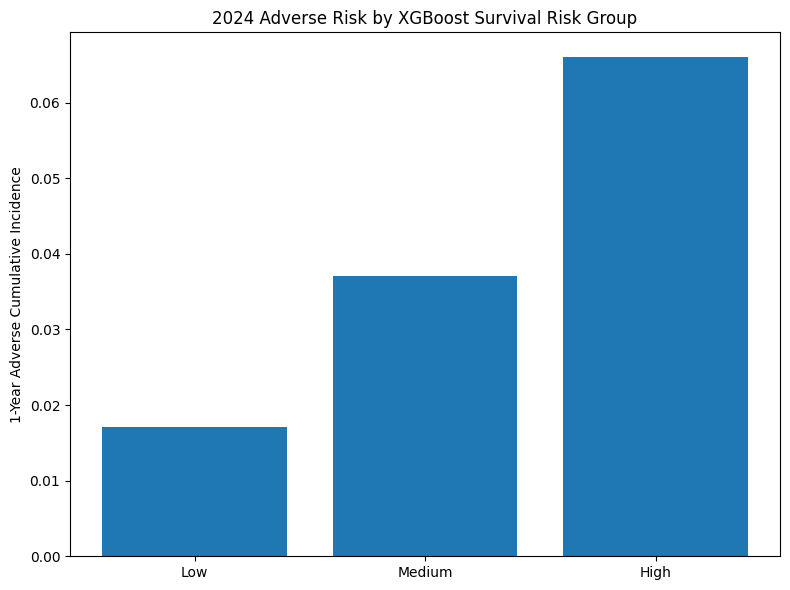

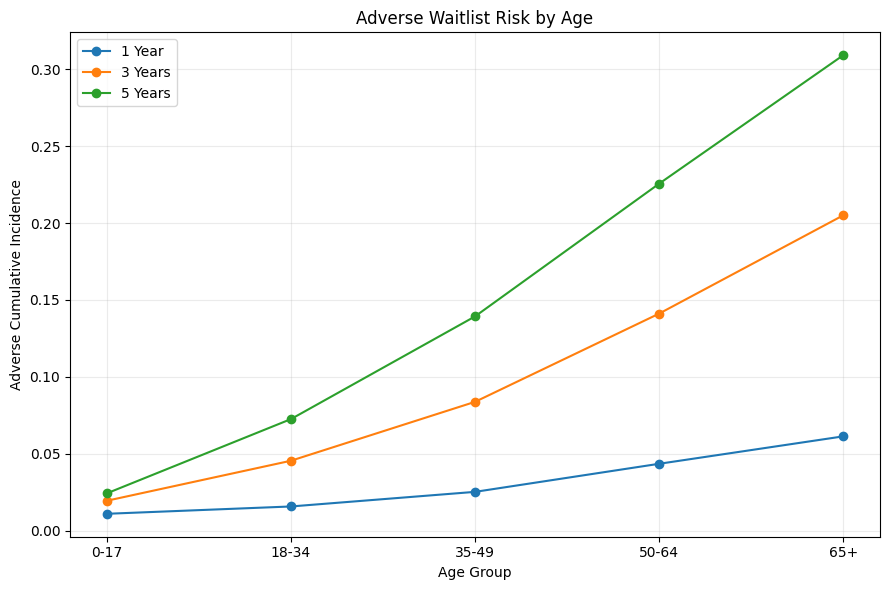

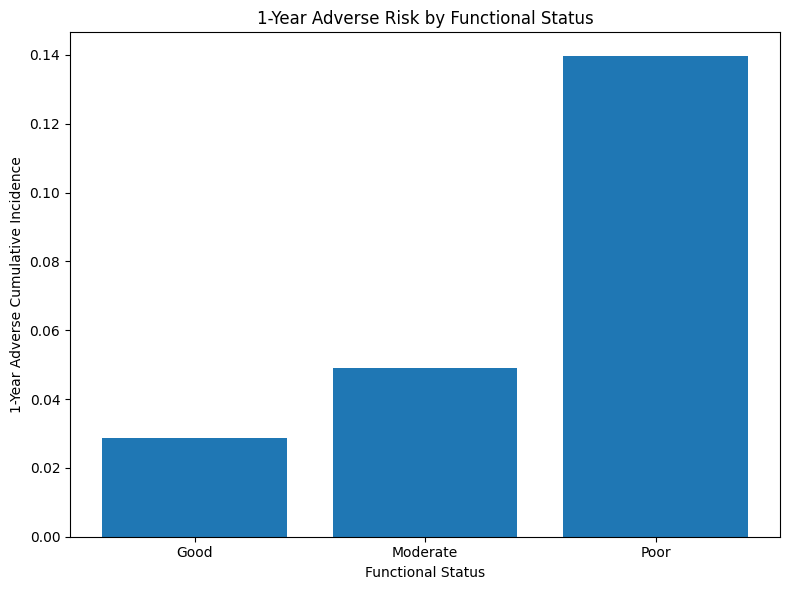


COMBINED FEATURE IMPORTANCE

            Feature  Classification_Importance  Survival_Importance  Average_Importance
           INIT_AGE                     31.590               34.860              33.225
FUNC_STAT_TCR_clean                     35.772               18.208              26.990
             REGION                      8.136               14.053              11.095
             ETHCAT                      6.552               10.341               8.446
        ON_DIALYSIS                      3.665                5.898               4.782
      BMI_TCR_clean                      4.991                3.420               4.205
       A2A2B_status                      3.069                3.402               3.235
             GENDER                      2.055                3.228               2.641
          INIT_STAT                      2.338                2.758               2.548
                ABO                      1.479                3.554               2.517
  

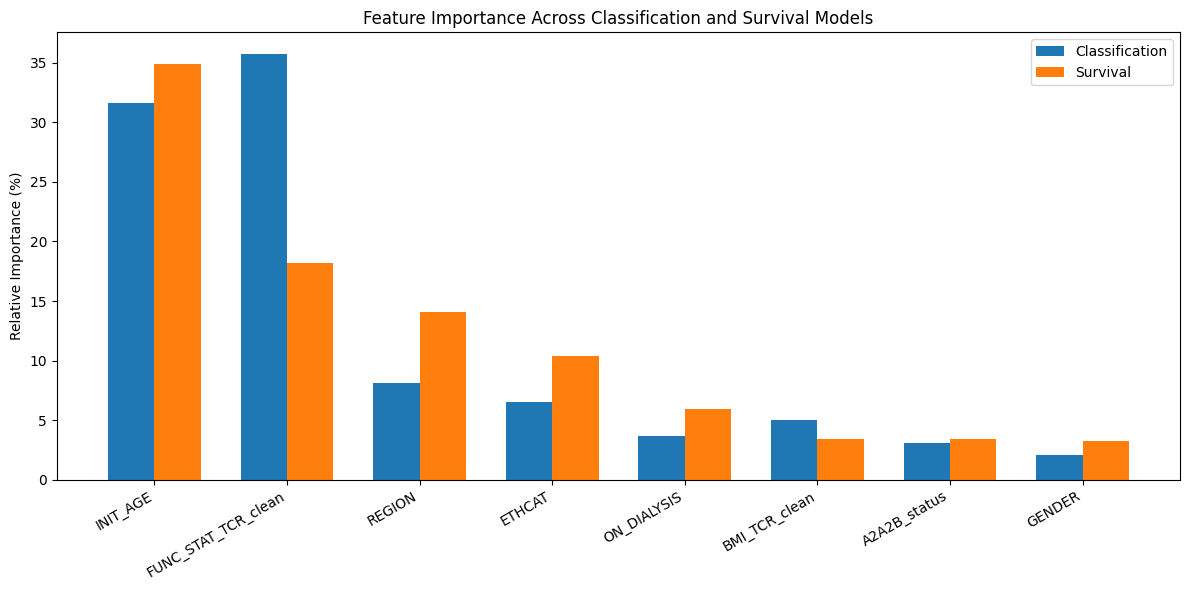


AGE SUBGROUP SYNTHESIS

AGE_GROUP     N  Adverse Rate  Average Predicted Risk  ROC-AUC  PR-AUC  Brier Score  Precision  Recall     F1  Adverse_1Y
     0-17  1091        0.0128                  0.0108   0.8353  0.0739       0.0124     0.0833  0.0714 0.0769      0.0109
    18-34  3806        0.0150                  0.0153   0.6209  0.0410       0.0146     0.1220  0.0877 0.1020      0.0157
    35-49 10089        0.0241                  0.0249   0.6355  0.0695       0.0231     0.1229  0.1193 0.1211      0.0252
    50-64 16722        0.0437                  0.0440   0.6210  0.0812       0.0413     0.0707  0.3986 0.1200      0.0435
      65+  9763        0.0575                  0.0650   0.6239  0.0995       0.0536     0.0704  0.7986 0.1293      0.0613

FINAL KEY FINDINGS

                            Finding                                           Result
               Classification model                                          XGBoost
        Classification test ROC-AUC                 

In [3]:
# ============================================================
# MEDIMATE KIDNEY WAITLIST — FINAL ANALYSIS
# CHUNK 2
#
# FINAL FIGURES
# + SUBGROUP SYNTHESIS
# + EXPLAINABILITY COMPARISON
# + KEY FINDINGS
# ============================================================

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


# ============================================================
# PART 1 — LOAD ALL CLASSIFICATION FAIRNESS TABLES
# ============================================================

fairness_age = pd.read_csv(
    os.path.join(
        classification_dir,
        "fairness_age.csv"
    )
)

fairness_gender = pd.read_csv(
    os.path.join(
        classification_dir,
        "fairness_gender.csv"
    )
)

fairness_ethcat = pd.read_csv(
    os.path.join(
        classification_dir,
        "fairness_ethcat.csv"
    )
)

fairness_abo = pd.read_csv(
    os.path.join(
        classification_dir,
        "fairness_blood_type.csv"
    )
)

fairness_region = pd.read_csv(
    os.path.join(
        classification_dir,
        "fairness_region.csv"
    )
)


# ============================================================
# PART 2 — LOAD ALL SURVIVAL SUBGROUP TABLES
# ============================================================

survival_age = pd.read_csv(
    os.path.join(
        survival_dir,
        "competing_risk_age.csv"
    )
)

survival_gender = pd.read_csv(
    os.path.join(
        survival_dir,
        "competing_risk_gender.csv"
    )
)

survival_ethcat = pd.read_csv(
    os.path.join(
        survival_dir,
        "competing_risk_ethcat.csv"
    )
)

survival_abo = pd.read_csv(
    os.path.join(
        survival_dir,
        "competing_risk_blood_type.csv"
    )
)

survival_dialysis = pd.read_csv(
    os.path.join(
        survival_dir,
        "competing_risk_dialysis.csv"
    )
)

survival_functional = pd.read_csv(
    os.path.join(
        survival_dir,
        "competing_risk_functional_status.csv"
    )
)


# ============================================================
# PART 3 — FINAL ANALYSIS OUTPUT DIRECTORY
# ============================================================

final_output_dir = (
    "/content/"
    "medimate_final_analysis_outputs"
)

os.makedirs(
    final_output_dir,
    exist_ok=True
)


# ============================================================
# PART 4 — FIGURE 1
# CLASSIFICATION VALIDATION VS TEST
# ============================================================

classification_plot_metrics = (
    classification_test_summary[
        classification_test_summary[
            "Metric"
        ].isin(
            [
                "ROC-AUC",
                "PR-AUC",
                "Precision at Fixed Threshold",
                "Recall at Fixed Threshold",
                "F1 at Fixed Threshold"
            ]
        )
    ]
    .copy()
)


x = np.arange(
    len(
        classification_plot_metrics
    )
)

width = 0.35


plt.figure(
    figsize=(11, 6)
)

plt.bar(
    x - width / 2,
    classification_plot_metrics[
        "Validation 2023"
    ],
    width,
    label="Validation 2023"
)

plt.bar(
    x + width / 2,
    classification_plot_metrics[
        "Test 2024"
    ],
    width,
    label="Test 2024"
)

plt.xticks(
    x,
    classification_plot_metrics[
        "Metric"
    ],
    rotation=25,
    ha="right"
)

plt.ylabel(
    "Score"
)

plt.title(
    "Classification Performance: "
    "2023 Validation vs 2024 Test"
)

plt.legend()

plt.tight_layout()

plt.savefig(
    os.path.join(
        final_output_dir,
        "classification_validation_vs_test.png"
    ),
    dpi=200,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# PART 5 — FIGURE 2
# CLASSIFICATION TOP FEATURES
# ============================================================

classification_feature_plot = (
    classification_shap
    .head(8)
    .copy()
    .sort_values(
        "Relative Importance %"
    )
)


plt.figure(
    figsize=(9, 6)
)

plt.barh(
    classification_feature_plot[
        "Original Feature"
    ],
    classification_feature_plot[
        "Relative Importance %"
    ]
)

plt.xlabel(
    "Relative Importance (%)"
)

plt.title(
    "Top Features in 1-Year Classification Model"
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        final_output_dir,
        "classification_top_features.png"
    ),
    dpi=200,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# PART 6 — FIGURE 3
# SURVIVAL TOP FEATURES
# ============================================================

survival_feature_plot = (
    survival_explainability
    .head(8)
    .copy()
    .sort_values(
        "Relative_Contribution_Percent"
    )
)


plt.figure(
    figsize=(9, 6)
)

plt.barh(
    survival_feature_plot[
        "Original_Variable"
    ],
    survival_feature_plot[
        "Relative_Contribution_Percent"
    ]
)

plt.xlabel(
    "Relative Contribution (%)"
)

plt.title(
    "Top Features in XGBoost Survival Model"
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        final_output_dir,
        "survival_top_features.png"
    ),
    dpi=200,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# PART 7 — FIGURE 4
# OVERALL COMPETING RISKS
# ============================================================

plt.figure(
    figsize=(9, 6)
)

plt.plot(
    overall_competing_risk[
        "Years"
    ],
    overall_competing_risk[
        "Adverse_Cumulative_Incidence"
    ],
    marker="o",
    label="Adverse Outcome"
)

plt.plot(
    overall_competing_risk[
        "Years"
    ],
    overall_competing_risk[
        "Transplant_Cumulative_Incidence"
    ],
    marker="o",
    label="Transplant"
)

plt.xlabel(
    "Years Since Waitlist Registration"
)

plt.ylabel(
    "Cumulative Incidence"
)

plt.title(
    "Kidney Waitlist Outcomes Over Time"
)

plt.xticks(
    overall_competing_risk[
        "Years"
    ]
)

plt.legend()

plt.grid(
    alpha=0.25
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        final_output_dir,
        "overall_competing_risk.png"
    ),
    dpi=200,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# PART 8 — FIGURE 5
# 2024 SURVIVAL RISK GROUPS
# ============================================================

plt.figure(
    figsize=(8, 6)
)

plt.bar(
    survival_risk_groups[
        "Risk_Group"
    ],
    survival_risk_groups[
        "Adverse_1Y_CIF"
    ]
)

plt.ylabel(
    "1-Year Adverse Cumulative Incidence"
)

plt.title(
    "2024 Adverse Risk by "
    "XGBoost Survival Risk Group"
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        final_output_dir,
        "survival_1yr_risk_groups.png"
    ),
    dpi=200,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# PART 9 — FIGURE 6
# AGE AND ADVERSE SURVIVAL RISK
# ============================================================

age_plot = survival_age.copy()


plt.figure(
    figsize=(9, 6)
)

plt.plot(
    age_plot[
        "AGE_GROUP"
    ].astype(str),
    age_plot[
        "Adverse_1Y"
    ],
    marker="o",
    label="1 Year"
)

plt.plot(
    age_plot[
        "AGE_GROUP"
    ].astype(str),
    age_plot[
        "Adverse_3Y"
    ],
    marker="o",
    label="3 Years"
)

plt.plot(
    age_plot[
        "AGE_GROUP"
    ].astype(str),
    age_plot[
        "Adverse_5Y"
    ],
    marker="o",
    label="5 Years"
)

plt.xlabel(
    "Age Group"
)

plt.ylabel(
    "Adverse Cumulative Incidence"
)

plt.title(
    "Adverse Waitlist Risk by Age"
)

plt.legend()

plt.grid(
    alpha=0.25
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        final_output_dir,
        "survival_age_risk.png"
    ),
    dpi=200,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# PART 10 — FIGURE 7
# FUNCTIONAL STATUS AND ADVERSE RISK
# ============================================================

func_plot = (
    survival_functional
    .copy()
)


func_order = [
    "Good",
    "Moderate",
    "Poor"
]


func_plot[
    "FUNC_GROUP"
] = pd.Categorical(
    func_plot[
        "FUNC_GROUP"
    ],
    categories=func_order,
    ordered=True
)


func_plot = (
    func_plot
    .sort_values(
        "FUNC_GROUP"
    )
)


plt.figure(
    figsize=(8, 6)
)

plt.bar(
    func_plot[
        "FUNC_GROUP"
    ].astype(str),
    func_plot[
        "Adverse_1Y"
    ]
)

plt.xlabel(
    "Functional Status"
)

plt.ylabel(
    "1-Year Adverse Cumulative Incidence"
)

plt.title(
    "1-Year Adverse Risk by Functional Status"
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        final_output_dir,
        "functional_status_1yr_risk.png"
    ),
    dpi=200,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# PART 11 — COMBINE CLASSIFICATION + SURVIVAL
# FEATURE IMPORTANCE
# ============================================================

class_feature_summary = (
    classification_shap[
        [
            "Original Feature",
            "Relative Importance %"
        ]
    ]
    .rename(
        columns={
            "Original Feature":
                "Feature",

            "Relative Importance %":
                "Classification_Importance"
        }
    )
)


surv_feature_summary = (
    survival_explainability[
        [
            "Original_Variable",
            "Relative_Contribution_Percent"
        ]
    ]
    .rename(
        columns={
            "Original_Variable":
                "Feature",

            "Relative_Contribution_Percent":
                "Survival_Importance"
        }
    )
)


# ------------------------------------------------------------
# Rename survival transformed features
# to original feature names
# ------------------------------------------------------------

survival_name_map = {
    "AGE_10Y":
        "INIT_AGE",

    "FUNC_GROUP":
        "FUNC_STAT_TCR_clean",

    "BMI_5":
        "BMI_TCR_clean"
}


surv_feature_summary[
    "Feature"
] = (
    surv_feature_summary[
        "Feature"
    ]
    .replace(
        survival_name_map
    )
)


combined_feature_importance = pd.merge(
    class_feature_summary,
    surv_feature_summary,
    on="Feature",
    how="outer"
)


combined_feature_importance = (
    combined_feature_importance
    .fillna(0)
)


combined_feature_importance[
    "Average_Importance"
] = (
    (
        combined_feature_importance[
            "Classification_Importance"
        ]
        +
        combined_feature_importance[
            "Survival_Importance"
        ]
    )
    / 2
)


combined_feature_importance = (
    combined_feature_importance
    .sort_values(
        "Average_Importance",
        ascending=False
    )
    .reset_index(
        drop=True
    )
)


print(
    "\n=========================================="
)

print(
    "COMBINED FEATURE IMPORTANCE"
)

print(
    "==========================================\n"
)


print(
    combined_feature_importance
    .round(3)
    .to_string(
        index=False
    )
)


# ============================================================
# PART 12 — FIGURE 8
# COMBINED FEATURE IMPORTANCE
# ============================================================

combined_plot = (
    combined_feature_importance
    .head(8)
    .copy()
)


x = np.arange(
    len(
        combined_plot
    )
)

width = 0.35


plt.figure(
    figsize=(12, 6)
)

plt.bar(
    x - width / 2,
    combined_plot[
        "Classification_Importance"
    ],
    width,
    label="Classification"
)

plt.bar(
    x + width / 2,
    combined_plot[
        "Survival_Importance"
    ],
    width,
    label="Survival"
)

plt.xticks(
    x,
    combined_plot[
        "Feature"
    ],
    rotation=30,
    ha="right"
)

plt.ylabel(
    "Relative Importance (%)"
)

plt.title(
    "Feature Importance Across "
    "Classification and Survival Models"
)

plt.legend()

plt.tight_layout()

plt.savefig(
    os.path.join(
        final_output_dir,
        "combined_feature_importance.png"
    ),
    dpi=200,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# PART 13 — AGE SUBGROUP SYNTHESIS
# ============================================================

classification_age_simple = (
    fairness_age
    .copy()
)


survival_age_simple = (
    survival_age[
        [
            "AGE_GROUP",
            "Adverse_1Y"
        ]
    ]
    .copy()
)


# Try to identify classification age column automatically
classification_age_col = None


for col in (
    classification_age_simple
    .columns
):

    if (
        "age" in col.lower()
        and
        "group" in col.lower()
    ):

        classification_age_col = col

        break


if classification_age_col is not None:

    classification_age_simple = (
        classification_age_simple
        .rename(
            columns={
                classification_age_col:
                    "AGE_GROUP"
            }
        )
    )


    age_synthesis = pd.merge(
        classification_age_simple,
        survival_age_simple,
        on="AGE_GROUP",
        how="inner"
    )


    print(
        "\n=========================================="
    )

    print(
        "AGE SUBGROUP SYNTHESIS"
    )

    print(
        "==========================================\n"
    )


    print(
        age_synthesis
        .round(4)
        .to_string(
            index=False
        )
    )


else:

    age_synthesis = (
        survival_age_simple.copy()
    )


# ============================================================
# PART 14 — FINAL KEY FINDINGS TABLE
# ============================================================

key_findings = pd.DataFrame(
    {
        "Finding": [

            "Classification model",

            "Classification test ROC-AUC",

            "Classification test PR-AUC",

            "Classification test recall",

            "Classification top-decile lift",

            "Survival model",

            "Survival test C-index",

            "Low-risk 1-year adverse incidence",

            "High-risk 1-year adverse incidence",

            "High vs low risk ratio",

            "Overall 1-year adverse incidence",

            "Overall 1-year transplant incidence",

            "Overall 5-year adverse incidence",

            "Overall 5-year transplant incidence",

            "Most important shared factors"
        ],

        "Result": [

            "XGBoost",

            "0.6742",

            "0.0860",

            "48.22%",

            "2.53x",

            "XGBoost Survival",

            "0.6784",

            "1.70%",

            "6.60%",

            "3.87x",

            "3.88%",

            "30.07%",

            "20.00%",

            "58.95%",

            (
                "Age, functional status, "
                "region, ETHCAT, dialysis"
            )
        ]
    }
)


print(
    "\n=========================================="
)

print(
    "FINAL KEY FINDINGS"
)

print(
    "==========================================\n"
)


print(
    key_findings
    .to_string(
        index=False
    )
)


# ============================================================
# PART 15 — FINAL SUBGROUP FINDINGS
# ============================================================

subgroup_findings = pd.DataFrame(
    {
        "Area": [
            "Age",
            "Functional status",
            "Dialysis",
            "Gender",
            "Blood type",
            "ETHCAT",
            "Region"
        ],

        "Main Finding": [

            (
                "Adverse risk rises strongly "
                "with age."
            ),

            (
                "Poorer functional status is "
                "associated with substantially "
                "higher adverse risk."
            ),

            (
                "Dialysis is associated with "
                "higher adjusted adverse hazard."
            ),

            (
                "Male and female classification "
                "recall was similar, although "
                "small risk differences remained."
            ),

            (
                "Blood type groups differ in "
                "transplant and adverse-event "
                "patterns."
            ),

            (
                "Performance and adverse-risk "
                "differences were observed across "
                "ETHCAT groups."
            ),

            (
                "Regional differences were present "
                "in both model behavior and "
                "outcome patterns."
            )
        ],

        "Interpretation": [

            "Association, not causation.",

            "Association, not causation.",

            "Adjusted association, not causation.",

            (
                "Differences should not automatically "
                "be interpreted as model bias."
            ),

            (
                "Likely influenced by compatibility "
                "and allocation processes."
            ),

            (
                "Requires careful fairness analysis; "
                "numeric ETHCAT codes should not be "
                "renamed without the official mapping."
            ),

            (
                "May reflect geography, access, "
                "center practices, or other factors."
            )
        ]
    }
)


print(
    "\n=========================================="
)

print(
    "SUBGROUP SYNTHESIS"
)

print(
    "==========================================\n"
)


print(
    subgroup_findings
    .to_string(
        index=False
    )
)


# ============================================================
# PART 16 — SAVE COMBINED TABLES
# ============================================================

combined_feature_importance.to_csv(
    os.path.join(
        final_output_dir,
        "combined_feature_importance.csv"
    ),
    index=False
)


key_findings.to_csv(
    os.path.join(
        final_output_dir,
        "final_key_findings.csv"
    ),
    index=False
)


subgroup_findings.to_csv(
    os.path.join(
        final_output_dir,
        "final_subgroup_findings.csv"
    ),
    index=False
)


master_summary.to_csv(
    os.path.join(
        final_output_dir,
        "primary_model_summary.csv"
    ),
    index=False
)


classification_test_summary.to_csv(
    os.path.join(
        final_output_dir,
        "classification_validation_vs_test.csv"
    ),
    index=False
)


overall_competing_risk.to_csv(
    os.path.join(
        final_output_dir,
        "overall_competing_risk.csv"
    ),
    index=False
)


survival_risk_groups.to_csv(
    os.path.join(
        final_output_dir,
        "survival_2024_risk_groups.csv"
    ),
    index=False
)


# ============================================================
# FINAL CHECK
# ============================================================

print(
    "\n=========================================="
)

print(
    "CHUNK 2 COMPLETE"
)

print(
    "=========================================="
)


print(
    "\nFinal figures and synthesis tables "
    "have been created and saved."
)

In [4]:
# ============================================================
# MEDIMATE KIDNEY WAITLIST — FINAL ANALYSIS
# CHUNK 3 — FINAL EXPORT + PROJECT CONCLUSION
# ============================================================

import os
import json
import shutil
import pandas as pd

from google.colab import files


# ============================================================
# PART 1 — CREATE FINAL EXECUTIVE SUMMARY TABLE
# ============================================================

executive_summary = pd.DataFrame({

    "Category": [
        "Classification",
        "Classification",
        "Classification",
        "Classification",
        "Survival",
        "Survival",
        "Survival",
        "Survival",
        "Competing Risks",
        "Competing Risks",
        "Shared Predictors"
    ],

    "Finding": [
        "Final model",
        "2024 ROC-AUC",
        "2024 PR-AUC",
        "Top-decile lift",
        "Final model",
        "2024 C-index",
        "High-risk 1-year adverse incidence",
        "High vs Low 1-year risk",
        "Overall 1-year adverse incidence",
        "Overall 5-year adverse incidence",
        "Most important shared factors"
    ],

    "Result": [
        "XGBoost",
        "0.6742",
        "0.0860",
        "2.53x",
        "XGBoost Survival",
        "0.6784",
        "6.60%",
        "3.87x",
        "3.88%",
        "20.00%",
        (
            "Age, functional status, "
            "region, ETHCAT, dialysis"
        )
    ]
})


executive_summary.to_csv(
    os.path.join(
        final_output_dir,
        "executive_summary.csv"
    ),
    index=False
)


print(
    "=========================================="
)

print(
    "EXECUTIVE SUMMARY"
)

print(
    "==========================================\n"
)


print(
    executive_summary
    .to_string(
        index=False
    )
)


# ============================================================
# PART 2 — SAVE AGE SYNTHESIS
# ============================================================

age_synthesis.to_csv(
    os.path.join(
        final_output_dir,
        "age_subgroup_synthesis.csv"
    ),
    index=False
)


# ============================================================
# PART 3 — SAVE FINAL METRICS JSON
# ============================================================

final_project_metrics = {

    "project":
        "MediMate Kidney Waitlist Outcomes",

    "classification_model":
        "XGBoost",

    "classification_feature_set":
        "No CPRA",

    "classification_test_year":
        2024,

    "classification_test_roc_auc":
        0.6742361130972558,

    "classification_test_pr_auc":
        0.08595927098244749,

    "classification_test_precision":
        0.07184628237259816,

    "classification_test_recall":
        0.4822429906542056,

    "classification_test_f1":
        0.12506059137178865,

    "classification_top_decile_lift":
        2.5290461641987885,

    "classification_top10_capture":
        0.2529595015576324,

    "survival_model":
        "XGBoost Survival",

    "survival_test_year":
        2024,

    "survival_validation_c_index":
        0.6736829485962488,

    "survival_test_c_index":
        0.6784257655146161,

    "survival_low_risk_1yr_adverse":
        0.017043137671546055,

    "survival_medium_risk_1yr_adverse":
        0.03705427864761817,

    "survival_high_risk_1yr_adverse":
        0.06600031595495626,

    "survival_high_vs_low_ratio":
        3.8725449049880902,

    "overall_1yr_adverse_incidence":
        0.0388,

    "overall_1yr_transplant_incidence":
        0.3007,

    "overall_5yr_adverse_incidence":
        0.2000,

    "overall_5yr_transplant_incidence":
        0.5895,

    "patient_safe_survival_split":
        True,

    "survival_patient_overlap":
        0,

    "cpra_used_in_final_models":
        False,

    "main_shared_factors": [
        "Age",
        "Functional status",
        "Region",
        "ETHCAT",
        "Dialysis"
    ],

    "final_test_horizon":
        "1 year for predictive test evaluation"
}


with open(
    os.path.join(
        final_output_dir,
        "final_project_metrics.json"
    ),
    "w"
) as f:

    json.dump(
        final_project_metrics,
        f,
        indent=4
    )


# ============================================================
# PART 4 — CREATE FINAL WRITTEN PROJECT SUMMARY
# ============================================================

final_summary_text = """
MEDIMATE KIDNEY WAITLIST — FINAL ANALYSIS SUMMARY

PROJECT GOAL
The project studied kidney waitlist outcomes using two related
modeling approaches.

1. Classification:
   Predict whether a patient experiences an adverse outcome
   within one year.

2. Survival analysis:
   Study how adverse risk changes over time while accounting
   for censoring and transplant as a competing event.


CLASSIFICATION RESULTS
The final classification model was XGBoost.

The model was trained on older registrations, validated on 2023,
and tested on 2024.

Final 2024 results:

ROC-AUC: 0.6742
PR-AUC: 0.0860
Precision: 7.18%
Recall: 48.22%
F1: 0.1251
Top-decile lift: 2.53x

The highest-risk 10% of registrations contained about 25.3% of
all adverse outcomes.

Because adverse outcomes are rare, precision remained low even
though the model was useful for ranking higher-risk patients.


SURVIVAL RESULTS
The final survival prediction model was XGBoost Survival.

Validation C-index: 0.6737
2024 test C-index: 0.6784

The model separated the 2024 test cohort into clear risk groups.

Low-risk 1-year adverse incidence: 1.70%
Medium-risk: 3.71%
High-risk: 6.60%

The high-risk group had about 3.87 times the one-year adverse
incidence of the low-risk group.


COMPETING RISKS
Transplant is a major competing event because a transplanted
patient is no longer at risk of an adverse outcome on the same
waitlist registration.

Aalen-Johansen competing-risk analysis was therefore used for
describing actual outcome probabilities.

Overall cumulative incidence:

1 year:
Adverse outcome: 3.88%
Transplant: 30.07%

3 years:
Adverse outcome: 12.68%
Transplant: 48.15%

5 years:
Adverse outcome: 20.00%
Transplant: 58.95%


IMPORTANT FACTORS
Age and functional status were the strongest and most consistent
factors across both modeling approaches.

Classification importance:
Functional status: about 35.8%
Age: about 31.6%

Survival contribution:
Age: about 34.9%
Functional status: about 18.2%

Other important factors included region, ETHCAT, dialysis status,
BMI, blood type and gender.


ADJUSTED COX FINDINGS
The Cox proportional-hazards model was kept as an interpretable
secondary survival model.

Each additional 10 years of age was associated with about 30.5%
higher adverse-event hazard.

Dialysis was associated with about 15.0% higher hazard.

Moderate functional status had about 32.9% higher hazard than
good functional status.

Poor functional status had about 2.36 times the adverse-event
hazard of good functional status.

These are adjusted associations and should not be interpreted
as causal effects.


SUBGROUP FINDINGS
Adverse risk increased strongly with age.

Poorer functional status was associated with higher adverse risk.

Differences were also observed across ETHCAT, region, blood type,
dialysis status and gender.

Male and female classification recall was relatively similar,
but larger differences were seen for some other subgroups.

These differences do not automatically prove model bias.
They may also reflect differences in clinical condition,
geography, access, compatibility, allocation processes or other
factors not included in the models.


CPRA
CPRA was tested during classification modeling.

Adding CPRA produced almost no improvement in validation
performance, while recent-year CPRA values were heavily missing.

For this reason, the final classification and survival models
did not use CPRA.


LIMITATIONS
The dataset does not contain every possible clinical factor.

Adverse outcomes are relatively rare, which limits precision in
the classification model.

Recent cohorts have shorter follow-up.

The 2024 predictive survival evaluation should mainly be
interpreted at the one-year horizon.

Subgroup differences are descriptive and do not prove causation
or unfair treatment.

Model explanations describe model behavior, not causal effects.

These models are intended for research and risk stratification.
They should not be used alone to make clinical or organ-allocation
decisions.


FINAL CONCLUSION
The classification and survival analyses tell a consistent story.

XGBoost-based models provided the strongest predictive performance
for both one-year adverse-event classification and time-to-event
risk ranking.

Age and functional status were the strongest shared predictors.

The models were able to identify groups with meaningfully different
future adverse risk, but performance was moderate rather than
clinical-grade.

The results support using the models as research tools for
understanding kidney waitlist risk and identifying patterns that
may deserve further investigation.
"""


summary_path = os.path.join(
    final_output_dir,
    "final_project_summary.txt"
)


with open(
    summary_path,
    "w"
) as f:

    f.write(
        final_summary_text
    )


# ============================================================
# PART 5 — SAVE README
# ============================================================

readme_text = """
MEDIMATE FINAL ANALYSIS OUTPUTS

This folder contains final combined results from:

1. Kidney waitlist 1-year adverse classification
2. Survival / time-to-event modeling
3. Competing-risk analysis
4. Subgroup analysis
5. Model explainability

IMPORTANT:
Patient-level raw OPTN data should not be shared publicly.

The files in this final-analysis folder contain aggregated
results and figures only.

Primary models:
- Classification: XGBoost
- Survival: XGBoost Survival

Final predictive test year:
- 2024

Primary predictive survival horizon:
- 1 year

See final_project_summary.txt for the complete final findings.
"""


with open(
    os.path.join(
        final_output_dir,
        "README.txt"
    ),
    "w"
) as f:

    f.write(
        readme_text
    )


# ============================================================
# PART 6 — LIST FINAL FILES
# ============================================================

final_files = sorted(
    os.listdir(
        final_output_dir
    )
)


print(
    "\n=========================================="
)

print(
    "FINAL ANALYSIS FILES"
)

print(
    "==========================================\n"
)


for i, filename in enumerate(
    final_files,
    start=1
):

    print(
        f"{i}. {filename}"
    )


print(
    "\nTotal files:",
    len(final_files)
)


# ============================================================
# PART 7 — CREATE FINAL ZIP
# ============================================================

zip_base = (
    "/content/"
    "medimate_final_analysis_outputs"
)


zip_path = shutil.make_archive(
    zip_base,
    "zip",
    final_output_dir
)


zip_size_mb = (
    os.path.getsize(
        zip_path
    )
    /
    (1024 ** 2)
)


print(
    "\n=========================================="
)

print(
    "FINAL ZIP CREATED"
)

print(
    "==========================================\n"
)


print(
    "File:",
    zip_path
)

print(
    "Size:",
    round(
        zip_size_mb,
        2
    ),
    "MB"
)


# ============================================================
# PART 8 — FINAL NOTEBOOK CONCLUSION
# ============================================================

print(
    final_summary_text
)


print(
    "\n=========================================="
)

print(
    "FINAL ANALYSIS COMPLETE"
)

print(
    "=========================================="
)


print(
    "\nEDA: COMPLETE"
)

print(
    "DATA CLEANING: COMPLETE"
)

print(
    "MODEL PREPARATION: COMPLETE"
)

print(
    "CLASSIFICATION MODELING: COMPLETE"
)

print(
    "SURVIVAL MODELING: COMPLETE"
)

print(
    "FINAL ANALYSIS: COMPLETE"
)


# ============================================================
# PART 9 — DOWNLOAD FINAL ZIP
# ============================================================

files.download(
    zip_path
)

EXECUTIVE SUMMARY

         Category                            Finding                                           Result
   Classification                        Final model                                          XGBoost
   Classification                       2024 ROC-AUC                                           0.6742
   Classification                        2024 PR-AUC                                           0.0860
   Classification                    Top-decile lift                                            2.53x
         Survival                        Final model                                 XGBoost Survival
         Survival                       2024 C-index                                           0.6784
         Survival High-risk 1-year adverse incidence                                            6.60%
         Survival            High vs Low 1-year risk                                            3.87x
  Competing Risks   Overall 1-year adverse incidence           

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>